# Case Study 3: Logistic Regression – Predicting Titanic Survival
**Subject:** Fundamentals of Data Science

**Objective:** Build a logistic regression classifier that predicts whether a passenger survived the Titanic disaster (`Survived` = 1) from passenger attributes, evaluate it, interpret its coefficients, and deploy it with Streamlit (`app.py`).

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42

## 1. Data Exploration

In [64]:
df = pd.read_csv("titanic.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [65]:
# Feature names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [66]:
# Summary statistics: numeric features, then categorical features
print(df.describe().round(2))
print()
print(df.select_dtypes(exclude="number").describe())

       PassengerId  Survived  Pclass     Age   SibSp   Parch    Fare
count       891.00    891.00  891.00  714.00  891.00  891.00  891.00
mean        446.00      0.38    2.31   29.70    0.52    0.38   32.20
std         257.35      0.49    0.84   14.53    1.10    0.81   49.69
min           1.00      0.00    1.00    0.42    0.00    0.00    0.00
25%         223.50      0.00    2.00   20.12    0.00    0.00    7.91
50%         446.00      0.00    3.00   28.00    0.00    0.00   14.45
75%         668.50      1.00    3.00   38.00    1.00    0.00   31.00
max         891.00      1.00    3.00   80.00    8.00    6.00  512.33

                       Name   Sex  Ticket Cabin Embarked
count                   891   891     891   204      889
unique                  891     2     681   147        3
top     Dooley, Mr. Patrick  male  347082    G6        S
freq                      1   577       7     4      644


In [67]:
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing[missing["missing"] > 0]

,missing,percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


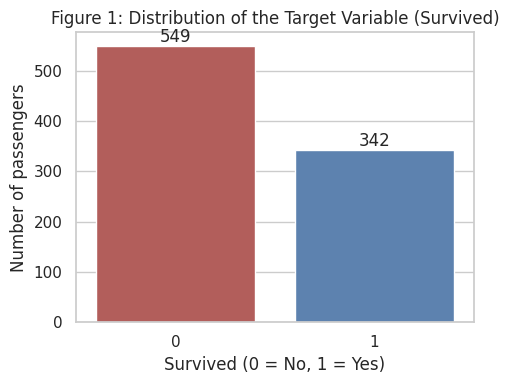

In [68]:
print(df["Survived"].value_counts())
print()
print((df["Survived"].value_counts(normalize=True) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Survived", data=df, hue="Survived", palette=["#c0504d", "#4f81bd"], legend=False, ax=ax)
ax.set_title("Figure 1: Distribution of the Target Variable (Survived)")
ax.set_xlabel("Survived (0 = No, 1 = Yes)")
ax.set_ylabel("Number of passengers")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()

Sex
female    74.2
male      18.9
Name: Survival rate (%), dtype: float64

Pclass
1    63.0
2    47.3
3    24.2
Name: Survival rate (%), dtype: float64

Embarked
C    55.4
Q    39.0
S    33.7
Name: Survival rate (%), dtype: float64



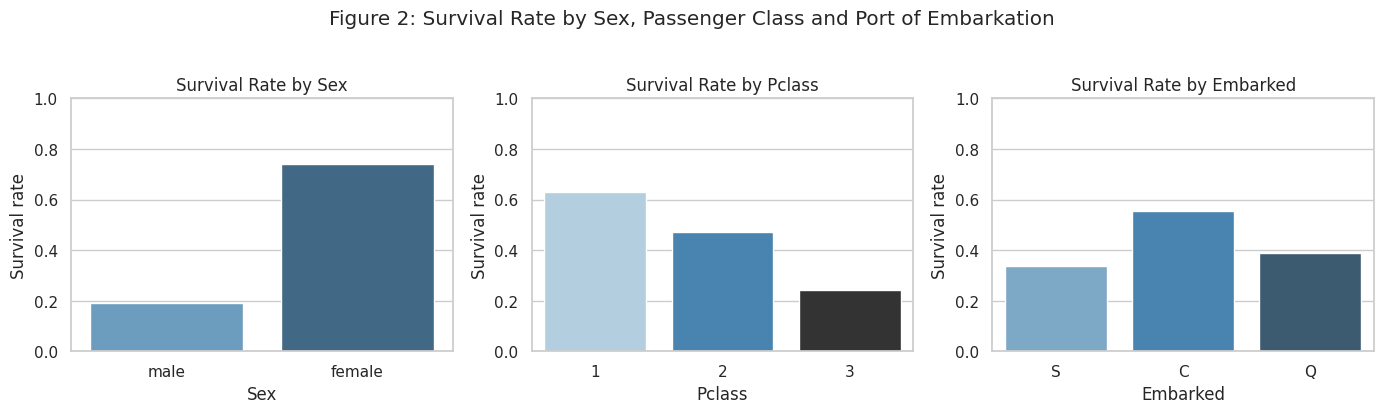

In [69]:
for col in ["Sex", "Pclass", "Embarked"]:
    print((df.groupby(col)["Survived"].mean() * 100).round(1).rename("Survival rate (%)"))
    print()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(x=col, y="Survived", data=df, hue=col, palette="Blues_d", legend=False, errorbar=None, ax=ax)
    ax.set_title(f"Survival Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1)
fig.suptitle("Figure 2: Survival Rate by Sex, Passenger Class and Port of Embarkation", y=1.03)
plt.tight_layout()
plt.show()

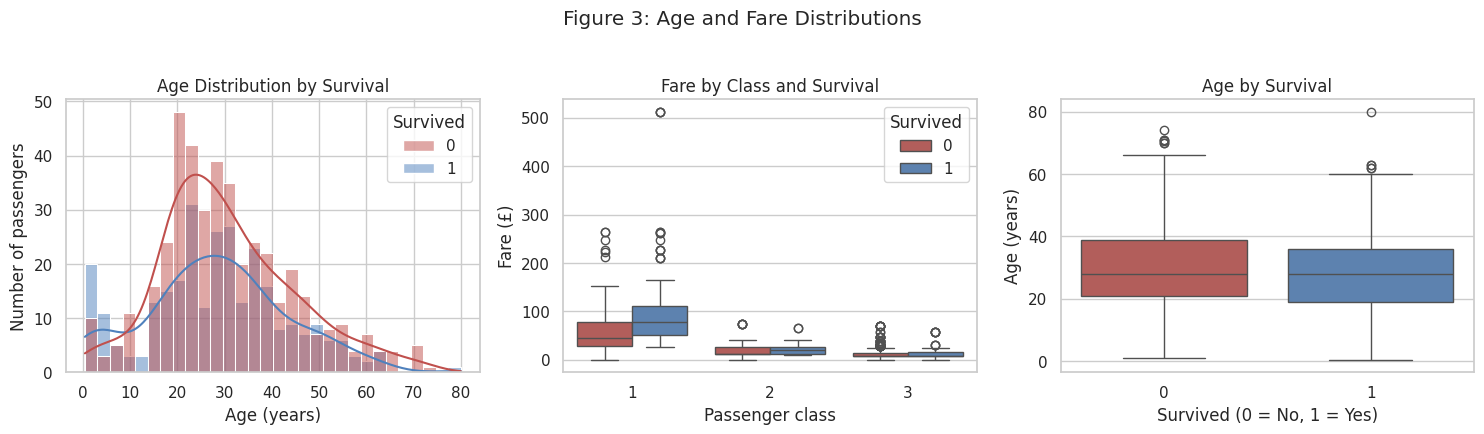

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, palette=["#c0504d", "#4f81bd"], ax=axes[0])
axes[0].set_title("Age Distribution by Survival")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of passengers")

sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived", palette=["#c0504d", "#4f81bd"], ax=axes[1])
axes[1].set_title("Fare by Class and Survival")
axes[1].set_xlabel("Passenger class")
axes[1].set_ylabel("Fare (£)")

sns.boxplot(data=df, x="Survived", y="Age", hue="Survived", palette=["#c0504d", "#4f81bd"], legend=False, ax=axes[2])
axes[2].set_title("Age by Survival")
axes[2].set_xlabel("Survived (0 = No, 1 = Yes)")
axes[2].set_ylabel("Age (years)")

fig.suptitle("Figure 3: Age and Fare Distributions", y=1.03)
plt.tight_layout()
plt.show()

Pclass     -0.338
Age        -0.077
SibSp      -0.035
Parch       0.082
Fare        0.257
Survived    1.000
Name: Survived, dtype: float64


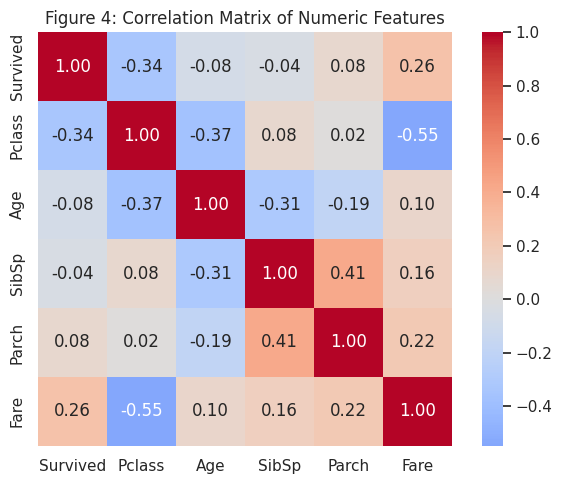

In [71]:
num = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]]
corr = num.corr()
print(corr["Survived"].round(3).sort_values())

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Figure 4: Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()


### Observations from the exploration

- **Class balance:** 342 of 891 passengers (38.4%) survived, so the target is moderately imbalanced. Accuracy alone can flatter a model here, so precision, recall, F1 and ROC-AUC are reported too.
- **Sex is the strongest pattern:** 74.2% of women survived against 18.9% of men (Figure 2), consistent with the "women and children first" evacuation policy.
- **Passenger class matters:** survival falls from 63.0% (1st class) to 47.3% (2nd) and 24.2% (3rd). `Pclass` has the strongest correlation with survival among the numeric features (r = -0.34, Figure 4).
- **Port of embarkation:** Cherbourg passengers survived more often (55.4%) than Queenstown (39.0%) or Southampton (33.7%). This is probably partly a class effect (a different passenger mix per port), which the model will help separate out.
- **Age:** the distributions overlap heavily and the medians are similar, but the histogram shows a clear excess of survivors among young children (Figure 3). The linear correlation with survival is weak (r = -0.08) because the effect is concentrated at the youngest ages.
- **Fare:** positively correlated with survival (r = 0.26), but fare is tightly linked to class (1st-class fares are far higher and highly skewed, with outliers above £500). Much of fare's apparent effect is likely a class effect.
- **Missing data:** `Age` is missing for 19.9% of passengers, `Cabin` for 77.1% and `Embarked` for 0.2%. These drive the preprocessing decisions below.


## 2. Data Preprocessing

In [72]:
data = df.copy()

# (a) Missing values
# Age: 19.9% missing -> impute with the median Age of the passenger's Pclass and Sex group
data["Age"] = data["Age"].fillna(data.groupby(["Pclass", "Sex"])["Age"].transform("median"))
# Embarked: only 2 missing -> impute with the most frequent port
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
# Cabin: 77% missing -> too sparse to impute reliably, so the column is dropped

# Identifiers / free text with no direct predictive meaning for a linear model
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# (b) Encode categorical variables
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})                # binary encoding (female = 1)
data = pd.get_dummies(data, columns=["Embarked"], drop_first=True, dtype=int)  # one-hot, baseline = Cherbourg (C)

print("Remaining missing values:", int(data.isna().sum().sum()))
print("Final columns:", list(data.columns))
data.head()

Remaining missing values: 0
Final columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


## 3. Model Building

In [73]:
X = data.drop(columns="Survived")
y = data["Survived"]

# 80/20 stratified split keeps the survival ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Survival rate - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (712, 8)  Test: (179, 8)
Survival rate - train: 0.383, test: 0.385


In [74]:
# Scaling inside a Pipeline so the test set is scaled with the training-set statistics (no leakage)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
print("Model trained. Features used:", list(X.columns))

Model trained. Features used: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']


## 4. Model Evaluation

In [75]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}
print(pd.Series(metrics).round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))
print("Train accuracy: %.4f | Test accuracy: %.4f" % (model.score(X_train, y_train), model.score(X_test, y_test)))

Accuracy     0.8212
Precision    0.8136
Recall       0.6957
F1-score     0.7500
ROC-AUC      0.8410

                 precision    recall  f1-score   support

Did not survive       0.82      0.90      0.86       110
       Survived       0.81      0.70      0.75        69

       accuracy                           0.82       179
      macro avg       0.82      0.80      0.81       179
   weighted avg       0.82      0.82      0.82       179

Train accuracy: 0.8076 | Test accuracy: 0.8212


[[99 11]
 [21 48]]


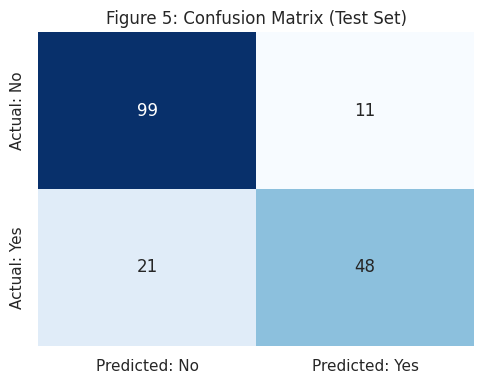

In [76]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted: No", "Predicted: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
ax.set_title("Figure 5: Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

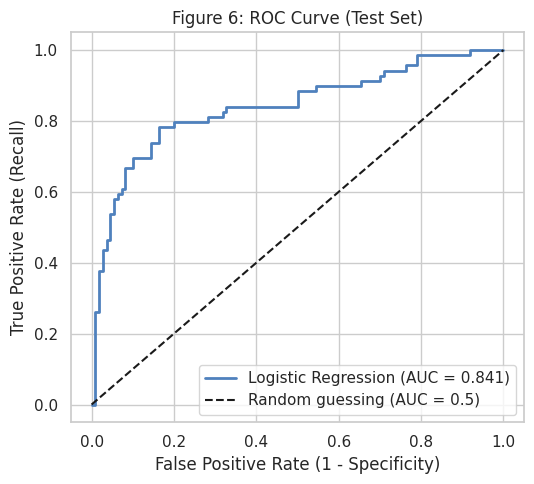

In [77]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#4f81bd", lw=2, label=f"Logistic Regression (AUC = {metrics['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")
ax.set_title("Figure 6: ROC Curve (Test Set)")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [78]:
# Robustness check: 5-fold stratified cross-validation on the full dataset
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
print("CV accuracy per fold:", cv_acc.round(3), "-> mean %.3f (+/- %.3f)" % (cv_acc.mean(), cv_acc.std()))
print("CV ROC-AUC per fold: ", cv_auc.round(3), "-> mean %.3f (+/- %.3f)" % (cv_auc.mean(), cv_auc.std()))

CV accuracy per fold: [0.788 0.809 0.787 0.792 0.82 ] -> mean 0.799 (+/- 0.013)
CV ROC-AUC per fold:  [0.876 0.853 0.831 0.828 0.881] -> mean 0.854 (+/- 0.022)



### Interpretation of the results

- **Accuracy 82.1%:** the model classifies about 4 in 5 test passengers correctly, well above the 61.5% obtained by always predicting "did not survive".
- **Precision 0.81:** when the model predicts survival, it is right about 81% of the time (48 true positives vs 11 false positives).
- **Recall 0.70:** it finds about 70% of the actual survivors; 21 survivors were missed (false negatives). The model is somewhat conservative, as it is more reliable at identifying who did *not* survive (recall 0.90 for that class).
- **F1-score 0.75:** the balance of precision and recall for the survivor class.
- **ROC-AUC 0.84:** if we pick one survivor and one non-survivor at random, the model assigns the survivor the higher probability about 84% of the time, so it separates the two groups well across all thresholds (Figure 6).
- **No sign of overfitting:** train accuracy (80.8%) is similar to test accuracy (82.1%). Five-fold cross-validation gives a mean accuracy of 79.9% (±1.3%) and AUC of 0.854 (±0.022), so the test result is slightly optimistic and roughly 80% accuracy is the realistic expectation.


## 5. Interpretation

In [79]:
# Coefficients of the fitted pipeline are per 1 standard deviation (scaled features).
# Dividing by the scaler's std converts them back to the original units of each feature.
scaler, logreg = model.named_steps["scaler"], model.named_steps["logreg"]
coef_raw = logreg.coef_[0] / scaler.scale_

coef_table = pd.DataFrame({
    "Coefficient (log-odds per unit)": coef_raw,
    "Odds ratio = exp(coef)": np.exp(coef_raw),
    "Std. coefficient (per 1 SD)": logreg.coef_[0],
}, index=X.columns).round(4)
print("Intercept (raw units): %.4f" % (logreg.intercept_[0] - np.sum(logreg.coef_[0] * scaler.mean_ / scaler.scale_)))
coef_table.sort_values("Std. coefficient (per 1 SD)", key=abs, ascending=False)

Intercept (raw units): 2.8224


,Coefficient (log-odds per unit),Odds ratio = exp(coef),Std. coefficient (per 1 SD)
Sex,2.6331,13.9167,1.2602
Pclass,-1.2131,0.2973,-1.0105
Age,-0.0435,0.9574,-0.5792
SibSp,-0.2701,0.7633,-0.2863
Embarked_S,-0.3537,0.7021,-0.1575
Fare,0.0019,1.0019,0.0903
Parch,-0.0774,0.9255,-0.0649
Embarked_Q,0.2418,1.2736,0.0646


In [80]:
# Significance: Wald z-tests from an (essentially) unpenalised fit on the training data.
# (scikit-learn does not report p-values, so they are computed from the Fisher information matrix.)
Xd = np.column_stack([np.ones(len(X_train)), X_train.values.astype(float)])
lr_np = LogisticRegression(C=1e10, max_iter=5000).fit(X_train, y_train)   # C very large = no regularisation
beta = np.r_[lr_np.intercept_, lr_np.coef_[0]]
p_hat = 1 / (1 + np.exp(-Xd @ beta))
W = p_hat * (1 - p_hat)
cov = np.linalg.inv(Xd.T @ (Xd * W[:, None]))
se = np.sqrt(np.diag(cov))
z = beta / se
pvals = 2 * (1 - stats.norm.cdf(np.abs(z)))

sig = pd.DataFrame({
    "coef": beta, "std_err": se, "z": z, "p_value": pvals,
    "odds_ratio": np.exp(beta),
    "OR 95% CI low": np.exp(beta - 1.96 * se), "OR 95% CI high": np.exp(beta + 1.96 * se),
}, index=["Intercept"] + list(X.columns))
sig["significant (p<0.05)"] = np.where(sig["p_value"] < 0.05, "Yes", "No")
sig.round(4)

,coef,std_err,z,p_value,odds_ratio,OR 95% CI low,OR 95% CI high,significant (p<0.05)
Intercept,2.9294,0.6091,4.8094,0.0000,18.7160,5.6720,61.7573,Yes
Pclass,-1.2463,0.1718,-7.2544,0.0000,0.2876,0.2053,0.4027,Yes
Sex,2.6714,0.2246,11.8939,0.0000,14.4603,9.3109,22.4577,Yes
Age,-0.0449,0.0091,-4.9548,0.0000,0.9561,0.9393,0.9732,Yes
SibSp,-0.2781,0.1227,-2.2673,0.0234,0.7572,0.5954,0.9630,Yes
Parch,-0.0796,0.1275,-0.6241,0.5325,0.9235,0.7193,1.1857,No
Fare,0.0017,0.0029,0.5944,0.5522,1.0017,0.9961,1.0074,No
Embarked_Q,0.2517,0.4467,0.5635,0.5731,1.2862,0.5359,3.0868,No
Embarked_S,-0.3534,0.2651,-1.3330,0.1825,0.7023,0.4177,1.1808,No


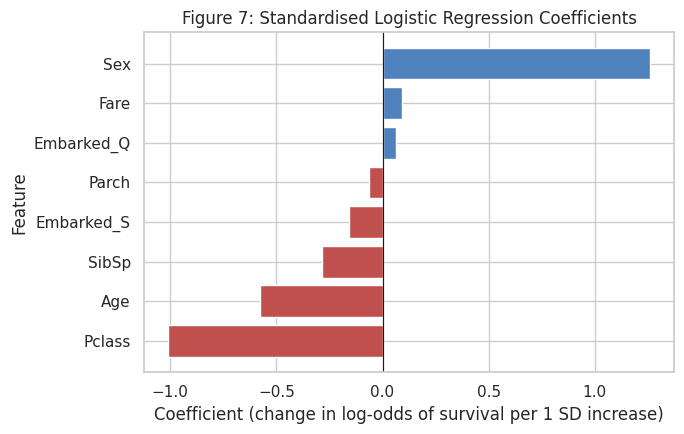

In [81]:
plot_df = coef_table["Std. coefficient (per 1 SD)"].sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(plot_df.index, plot_df.values, color=np.where(plot_df.values > 0, "#4f81bd", "#c0504d"))
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Figure 7: Standardised Logistic Regression Coefficients")
ax.set_xlabel("Coefficient (change in log-odds of survival per 1 SD increase)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()


### Interpretation of coefficients

A logistic regression models the **log-odds** of survival. Exponentiating a coefficient gives an **odds ratio** (OR): the multiplicative change in the odds of survival for a one-unit increase in that feature, holding the others fixed.

| Feature | Odds ratio | Meaning | Significant (p < 0.05)? |
|---|---|---|---|
| `Sex` (female = 1) | ≈ 14 | Women have about 14 times the odds of survival of men with the same class, age and family size | Yes (p < 0.001) |
| `Pclass` | ≈ 0.29 | Each step down in class (1st → 2nd → 3rd) cuts the odds of survival by about 70% | Yes (p < 0.001) |
| `Age` | ≈ 0.96 | Each additional year lowers the odds by about 4%; 10 years older ≈ 35% lower odds | Yes (p < 0.001) |
| `SibSp` | ≈ 0.76 | Each additional sibling/spouse aboard lowers the odds by about 24% | Yes (p = 0.023) |
| `Parch` | ≈ 0.92 | No clear effect | No (p = 0.53) |
| `Fare` | ≈ 1.00 | No effect once class is accounted for | No (p = 0.55) |
| `Embarked_Q`, `Embarked_S` | 1.28, 0.70 (vs Cherbourg) | No clear effect once other features are accounted for | No (p = 0.58, 0.18) |

**Feature importance.** Comparing the standardised coefficients (Figure 7), which are on a common scale, the ranking is `Sex` (1.26) > `Pclass` (-1.01) > `Age` (-0.58) > `SibSp` (-0.29). The remaining features contribute very little.

**Caveats.**
- Odds ratios describe odds, not probabilities. An OR of 14 does not mean women were 14 times as likely to survive.
- These are associations in historical data, not causal effects.
- `Pclass` is treated as numeric, which assumes each class step has the same effect, and `Age` is assumed to act linearly, although the exploration suggested a stronger effect for young children. Adding a child indicator or non-linear age terms is a natural improvement.
- The p-values come from a separate, essentially unregularised fit on the training set (scikit-learn does not report them). The coefficients are very close to those of the deployed regularised model.


## 6. Deployment with Streamlit

In [82]:
# Save the trained pipeline (scaler + model) and the feature order for the Streamlit app
joblib.dump({"model": model, "features": list(X.columns)}, "titanic_model.joblib")
print("Saved titanic_model.joblib")

Saved titanic_model.joblib


The saved pipeline is loaded by `app.py`, which collects passenger details through input widgets and displays the predicted survival probability.

Run it locally with:
```
pip install -r requirements.txt
streamlit run app.py
```
For online deployment, push this folder to GitHub and deploy `app.py` from [Streamlit Community Cloud](https://docs.streamlit.io/streamlit-community-cloud/deploy-your-app).